In [1]:
# Colab only: clone (or update) the repo on the main branch and move into the project root
import os
import sys

if 'google.colab' in sys.modules:
    REPO = '/content/convolutional_vae_quishing'
    BRANCH = 'main'
    if not os.path.exists(REPO):
        !git clone -b {BRANCH} https://github.com/AnhJoe/convolutional_vae_quishing.git {REPO}
    else:
        !git -C {REPO} fetch origin
        !git -C {REPO} checkout {BRANCH}
        !git -C {REPO} pull origin {BRANCH}
    os.chdir(REPO)

remote: Enumerating objects: 23, done.
remote: Counting objects: 100% (23/23), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 12 (delta 8), reused 12 (delta 8), pack-reused 0 (from 0)
Unpacking objects: 100% (12/12), 105.99 KiB | 2.72 MiB/s, done.
From https://github.com/AnhJoe/convolutional_vae_quishing
   3ba8630..666b6ce  joe        -> origin/joe
Already on 'joe'
Your branch is behind 'origin/joe' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/AnhJoe/convolutional_vae_quishing
 * branch            joe        -> FETCH_HEAD
Updating 3ba8630..666b6ce
Fast-forward
 .../275p_Project_Proposal_URL_VAE_revised.docx     |  Bin 682265 -> 682422 bytes
 notebooks/4_url_vae.ipynb                          | 1055 +++++++++++++++-----
 notebooks/5_supervised_reference.ipynb             |  511 +++++++++-
 notebooks/6_results.ipynb                          |   69 +-
 src/analysis.py                                    

In [2]:
# Colab only: mount Google Drive and link the data, results and model folders to it, so they survive a disconnect
import os
import sys

if 'google.colab' in sys.modules:
    from google.colab import drive

    drive.mount('/content/drive')

    REPO_DIR = '/content/convolutional_vae_quishing'
    DRIVE_DIR = '/content/drive/MyDrive/quishing'    # holds processed/items.csv.gz and processed/items_summary.json

    for sub in ('processed', 'results', 'artifacts'):
        os.makedirs(f'{DRIVE_DIR}/{sub}', exist_ok=True)
    for needed in ('items.csv.gz', 'items_summary.json'):
        if not os.path.exists(f'{DRIVE_DIR}/processed/{needed}'):
            raise FileNotFoundError(f'Copy {needed} from data/processed on your computer to {DRIVE_DIR}/processed/')

    os.makedirs(f'{REPO_DIR}/data', exist_ok=True)
    for link, target in ((f'{REPO_DIR}/data/processed', 'processed'),
                         (f'{REPO_DIR}/data/artifacts', 'artifacts'),
                         (f'{REPO_DIR}/results', 'results')):
        if not os.path.lexists(link):
            os.symlink(f'{DRIVE_DIR}/{target}', link)
    print('Drive linked:', DRIVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive linked: /content/drive/MyDrive/quishing


In [3]:
#| output: false
# Find the project root (the folder containing src/) and add it to the import path. Run this on Colab too.

import sys
from pathlib import Path

# Set to root for src load
root = Path.cwd()
while root != root.parent and not (root / "src").exists():
    root = root.parent

if not (root / "src").exists():
    raise FileNotFoundError("Could not find 'src' folder above current working directory.")

sys.path.insert(0, str(root))
print("Project root:", root)

Project root: /content/convolutional_vae_quishing


# URL VAE

A **variational autoencoder (VAE)** learns to compress a URL into a short code (a handful of numbers, called the latent code `z`) and to rebuild the URL from that code. It is trained on **benign URLs only**. A URL that looks like the benign ones should be rebuilt well. A URL that looks different (the hope for malicious ones) should be rebuilt worse, and that gives an anomaly score without ever showing the model a malicious URL.

How this model works:

- The **encoder** (a GRU, a network that reads text one character at a time) reads the URL and produces a distribution over `z`.
- The **decoder** (also a GRU) writes the URL back one character at a time. At each step it sees `z` and the characters written so far, and predicts the next character. During training it is given the true previous character (this is called teacher forcing).
- **Training** maximizes the ELBO, which is the rebuilding quality minus a penalty (the KL term) that keeps the codes close to a standard bell curve. The penalty is switched on gradually (KL annealing), because otherwise the decoder can learn to ignore `z` entirely, which is called **posterior collapse**. The KL term is logged every epoch to catch this. A KL term that falls to about 0 means collapse.
- The **scores** (higher means more likely malicious) are both measured per character, so URL length does not enter through summation: `nll_per_char` (how surprised the decoder is by the URL, given the posterior mean code) and `neg_elbo_per_char` (the same plus the KL penalty).

The model is fitted on the benign train URLs only, and the best epoch is the one with the lowest negative ELBO per character on the benign validation URLs (no malicious URL and no label is used). One caution carried from the literature: a model that reconstructs well does not guarantee that it reconstructs anomalies badly (Bouman and Heskes, 2025), so detection quality is checked against the floors in `6_results.ipynb` instead of being assumed.

The code lives in `src/url_vae.py` (model, training, scoring) and `src/runner.py` (the run). This notebook only sets the settings and starts the run. Run `2_data_processing.ipynb` first, and `3_floors.ipynb` if you want the floors for comparison.

In [4]:
# Imports and settings
import json

from src import checks
from src.plots import plot_vae_history
from src.prepare_data import load_items
from src.runner import run_tuning, run_url_vae, trial_setup
from src.splits import SPLIT_NAMES
from src.url_vae import VAEConfig

PROC_DIR = root / "data" / "processed"
RESULTS_DIR = root / "results"
ARTIFACTS_DIR = root / "data" / "artifacts"     # model weights and training histories (git-ignored)

## 1. Data

`load_items` reads the items table built by `2_data_processing.ipynb` (one row per kept URL, with its label, split and URL features). The data checks below confirm that the table is the one everyone on the team should have.

In [5]:
# Load the items table and its summary, then count the URLs per split and class
items = load_items(PROC_DIR)
summary = json.loads((PROC_DIR / "items_summary.json").read_text())
items.groupby(["split", "cls"]).size().unstack().loc[SPLIT_NAMES]

cls,benign,malicious
split,,
train,300969,403020
validation,64494,86361
test,64494,86362


**Checks on the data.** The next cell runs a set of checks on the items table and prints one row per check. Each row is `pass` or `FAIL`, and the cell stops with an error if any check fails, so a broken table cannot reach a model by accident. The checks confirm that the table matches `items_summary.json` (the row counts and the data version, which everyone on the team should see as the same value), that every split has both classes, that no registered domain sits in two splits of the same class, and that the URL columns are consistent.

In [6]:
# Run the data checks on the items table (stops with an error if any check fails)
checks.data_checks(items, summary).report()

check,result,detail
row count matches items_summary.json,pass,"1,005,700 rows"
data version matches items_summary.json,pass,08d6fa626da8. Everyone on the team should see the same value
item_id equals the row position,pass,
label matches the class folder,pass,
rows per split and class match items_summary.json,pass,"train: 300,969 benign, 403,020 malicious; validation: 64,494 benign, 86,361 malicious; test: 64,494 benign, 86,362 malicious"
every split has benign and malicious rows,pass,
no domain appears in two splits of the same class,pass,
malicious share of every split is within 1 point of the overall share,pass,"train 0.572, validation 0.572, test 0.572 (overall 0.572)"
"no empty URL, and url_len equals the URL length",pass,
truncated is true exactly for URLs longer than 256,pass,"5,742 truncated"


**Checks on the model.** The next cell builds a tiny VAE on the CPU and tests the code, not a trained model: the output shapes, that the padding does not change a URL's loss, that the decoder is causal (a character only influences the predictions after it), that the KL term is zero for the prior, that an untrained model costs about `log(97)` nats per character, that a few training steps lower the cost, that scoring is repeatable, that the supervised reference has the same encoder as the VAE, that a finished seed is skipped and a changed setting retrains it, that the tuning sweep keeps the candidate with the lowest validation negative ELBO and trains nothing twice, and that training stops on a non-finite gradient.

In [7]:
# Run the model checks on a tiny network (CPU, about half a minute)
checks.model_checks(items).report()

check,result,detail
decoder gives one logit vector of 97 per character position,pass,"(8, 125, 97)"
the start token id is outside the character vocabulary,pass,
an untrained model costs about log(97) = 4.57 nats per character,pass,4.64 to 4.68
padding does not change a URL's loss (alone or inside a longer batch),pass,125.94955 vs 125.94955
the decoder is causal: changing character t does not change the predictions up to t,pass,
the decoder does read earlier characters: it changes the prediction after t,pass,
"KL to the prior is 0 for N(0, I) and positive otherwise",pass,
"scores are finite and positive, one row per URL",pass,
nll_per_char equals the reconstruction loss at z = mu divided by the URL length,pass,
scoring the same data twice gives the same scores (fixed noise),pass,


## 2. Settings

The defaults in `VAEConfig` are a small model (embedding 32, hidden size 64, a one-direction encoder, `latent=16`, 8 epochs, about 56 thousand parameters). Section 3 sweeps the latent size and `beta` around them on **validation data only**. The test set is used once per model, after the configuration is fixed. We run three seeds (0, 1, and 2).

`QUICK = True` runs a two-epoch trial on a small slice of the data and saves it under `results/quick`, to test that everything works before a long run. `TUNE = False` skips the sweep and trains the base settings.

In [8]:
# Settings: base model and training sizes, the seeds, and the quick trial and sweep switches
QUICK = False
TUNE = True                      # run the sweep of section 3 and train every seed with its winner
SEEDS = [0, 1, 2]                # three seeds (seed 0 is the sweep winner when TUNE = True)
base_cfg = VAEConfig(epochs=2, emb_dim=16, hidden=64, latent=8) if QUICK else VAEConfig()
run_items, res_dir, art_dir = trial_setup(items, RESULTS_DIR, ARTIFACTS_DIR, QUICK)
sources = summary.get("sources")     # checksums of the source CSVs, saved in every run record
base_cfg

VAEConfig(emb_dim=32, hidden=64, latent=16, bidirectional=False, epochs=8, batch_size=512, lr=0.002, grad_clip=5.0, beta=1.0, anneal_epochs=3.0, word_dropout=0.1, bucket_batches=50, score_samples=4)

## 3. Tuning sweep

The sweep trains the base VAE and then changes one setting at a time on seed 0: the latent size (8, 16, 32) and `beta` (0.01, 0.1, 1.0), which is five models. The winner is the one with the lowest negative ELBO per character on the **benign validation** URLs (at its best epoch). No label, no malicious URL, and no test URL is used. The winner is the seed 0 model in the next section and is not trained again.

Read the table with three cautions. The sweep uses seed 0 only and changes one setting at a time, so a small gap between candidates may be noise. The negative ELBO is measured with a KL weight of 1 for every candidate, which is the only way to compare them, but it also means the criterion favors `beta = 1` by construction. The `beta` rows can therefore show that a smaller `beta` is not needed for density, and cannot show that it helps detection. And the criterion is how well benign validation URLs are modeled, which is not the same as how well malicious ones are told apart.

Each candidate is saved under `data/artifacts/url_vae_tuning/`, and a rerun skips the ones already trained with the same settings and data. Set `TUNE = False` to skip this section.

In [9]:
# Train the sweep candidates on seed 0 (prints one line per epoch) and show them, best epoch of each, winner marked
tuning = run_tuning(run_items, art_dir, base_cfg) if TUNE else None
tuning.table.round(3) if TUNE else "TUNE is False: the base settings are used"


base: already trained with these settings, skipped
latent8: already trained with these settings, skipped
latent32: already trained with these settings, skipped
beta0.01: already trained with these settings, skipped
beta0.1: already trained with these settings, skipped


,candidate,latent,beta,best_epoch,val_neg_elbo_per_char,val_nll_per_char,val_kl,minutes,selected
0,base,16,1.00,7,2.175,2.131,0.861,0.882,False
1,latent8,8,1.00,7,2.177,2.121,1.221,0.818,False
2,latent32,32,1.00,7,2.173,2.131,0.932,0.825,True
3,beta0.01,16,0.01,3,3.415,1.974,45.641,0.835,False
4,beta0.1,16,0.10,7,2.672,1.856,25.223,0.829,False


## 4. Train

One VAE is trained on the benign train URLs for each seed in `SEEDS` (0, 1, and 2) and its scores are saved to `results/url_vae/<score>/seed<k>/`. With `TUNE = True`, seed 0 is the sweep winner: its scores are computed and saved without training it again, and seeds 1 and 2 are trained with the winner's settings. The model weights and the training history go to `data/artifacts/url_vae/seed<k>/`. Each finished seed also saves a run record (`run.json`) next to its scores with the settings, the data version, the environment (Python, numpy, pandas and torch versions, and the device), and the checksums of the source CSVs. A seed is skipped only when its scores exist and the record matches the current settings and data (the environment and checksums are saved for the report and are not compared), so an interrupted run can be restarted and a changed setting retrains instead of reusing old scores (the log says what changed; `overwrite=True` retrains everything). A local NVIDIA GPU is used when there is one. Batches hold URLs of similar length (`bucket_batches=50` in the settings). Set `bucket_batches=0` for random batches.

To compare another setting (an ablation), pass `model_name="url_vae_z16"` (any new name), which saves it beside the main run without overwriting it.

In [10]:
# Train the VAE and save both scores (the sweep winner is reused as seed 0)
cfg = tuning.best_config if TUNE else base_cfg
metrics, histories = run_url_vae(run_items, res_dir, art_dir, cfg, SEEDS,
                                 trained=tuning.winners() if TUNE else None, sources=sources)
cfg

URL VAE on cuda: 300,969 benign train URLs, 64,494 benign validation URLs, 8 epochs
seed 0: score files and run record match, skipped (overwrite=True to rerun)
seed 1
  epoch  1/8  beta 0.33  train rec/char 2.758  KL 5.7  | val -ELBO/char 2.357  val KL 1.8  (best)  7s
  epoch  2/8  beta 0.67  train rec/char 2.324  KL 2.6  | val -ELBO/char 2.265  val KL 1.7  (best)  6s
  epoch  3/8  beta 1.00  train rec/char 2.235  KL 1.8  | val -ELBO/char 2.230  val KL 1.1  (best)  6s
  epoch  4/8  beta 1.00  train rec/char 2.197  KL 1.4  | val -ELBO/char 2.204  val KL 1.0  (best)  6s
  epoch  5/8  beta 1.00  train rec/char 2.167  KL 1.3  | val -ELBO/char 2.191  val KL 0.9  (best)  6s
  epoch  6/8  beta 1.00  train rec/char 2.147  KL 1.3  | val -ELBO/char 2.182  val KL 1.0  (best)  6s
  epoch  7/8  beta 1.00  train rec/char 2.130  KL 1.4  | val -ELBO/char 2.175  val KL 0.9  (best)  6s
  epoch  8/8  beta 1.00  train rec/char 2.119  KL 1.3  | val -ELBO/char 2.170  val KL 0.9  (best)  6s
seed 2
  epoch  1

VAEConfig(emb_dim=32, hidden=64, latent=32, bidirectional=False, epochs=8, batch_size=512, lr=0.002, grad_clip=5.0, beta=1.0, anneal_epochs=3.0, word_dropout=0.1, bucket_batches=50, score_samples=4)

## 5. Training curves

Left: the reconstruction negative log-likelihood per character, on the training URLs (dashed, a running average over the epoch while `beta` is still rising) and on the benign validation URLs (solid). Lines that end close together mean the model is not overfitting. Middle: the KL term on the benign validation URLs. A line that stays near 0 means posterior collapse (the decoder ignores the code). If that happens, try a longer annealing (`anneal_epochs`), more word dropout (`word_dropout`) or a smaller `beta`. Right: the negative ELBO per character on the benign validation URLs. It should go down and flatten, and the lowest point marks the epoch that is kept.

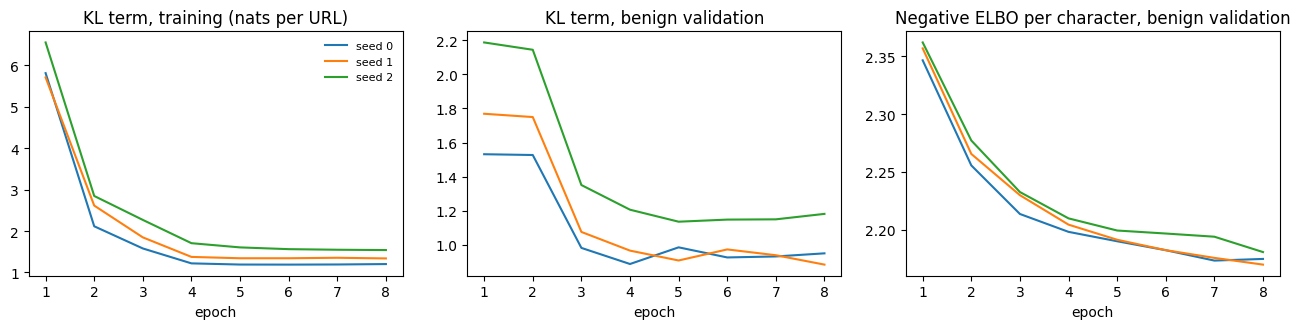

In [11]:
# Plot the reconstruction term, the validation KL term and the validation negative ELBO per epoch, one line per seed
plot_vae_history(histories);

## 6. Test metrics

One row per score and seed. The headline comparison with the floors, with confidence intervals, strata and the success criteria, is in `6_results.ipynb`. Do not choose settings by looking at these test numbers. Use `validation_auroc` for that.

In [ ]:
# Test metrics of every run (see 3_floors.ipynb for what each column means)
metrics[["score", "seed", "validation_auroc", "auroc", "auprc", "recall_at_1pct_fpr", "recall_at_5pct_fpr"]].round(3)